# 10 · `hate`: LLM vs HerBERT, Polbert, RoBERTa-BAN-PL na gold standardzie

Który sposób oznaczania hejtu lepiej zgadza się z gold standardem? Porównujemy **na tych samych komentarzach**:

- **klasyfikatory** z notebooka 08 (`reports/gold_model_eval/gold_predictions.csv`, wariant „słownik + model”),
- **LLM** z notebooka 09 (`reports/gold_llm_eval/gold_llm_labels.csv` – etykiety z `labeled/`, tak jak w analizach zespołu),
- sam słownik obelg (punkt odniesienia).

LLM ma etykiety tylko dla części wydarzeń, więc główne porównanie jest na wspólnym podzbiorze (sekcja 1). Klasyfikatory
na pełnych 600 komentarzach są w notebooku 08 (tu dla porównania w sekcji 1).

**Testy różnic (te same komentarze = próby zależne):**
- **McNemar (dokładny)** – czy dwie metody mylą się na różnych komentarzach częściej w jedną stronę (dotyczy accuracy),
- **różnica F1 z bootstrapu par** – 95% CI dla F1(LLM) − F1(model); przedział bez zera = istotna różnica,
- korekta Holma na liczbę porównań.

Uwaga: na YouTube i Bluesky LLM z założenia nie oznacza hejtu w komentarzach, które uznał za niezwiązane z migracją (notebook 09,
sekcja 3). Sekcja 3 pokazuje porównanie tylko na komentarzach, które LLM ocenił.

In [1]:
# ── KONFIGURACJA ──────────────────────────────────────────────────────────────
MODEL_PRED = "reports/gold_model_eval/gold_predictions.csv"    # notebook 08
LLM_LABELS = "reports/gold_llm_eval/gold_llm_labels.csv"       # notebook 09
OUT_DIR = "reports/gold_llm_eval"
METHODS = {   # nazwa -> kolumna z predykcją 0/1
    "LLM (Ollama, labeled/)": "llm_hate",
    "HerBERT-HS": "pred_herbert",
    "Polbert-CB": "pred_polbert",
    "RoBERTa-BAN-PL": "pred_roberta_banpl",
    "sam słownik": "hate_auto",
}
REFERENCE = "LLM (Ollama, labeled/)"     # z tym porównujemy pozostałe metody
N_BOOT = 2000
SEED = 2026
ALPHA = 0.05

In [2]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
OUT = ROOT / OUT_DIR
pd.set_option("display.max_colwidth", 180)
pd.set_option("display.width", 220)

mp = ROOT / MODEL_PRED
lp = ROOT / LLM_LABELS
assert mp.exists(), "brak predykcji modeli – odpal notebook 08_gold_standard_eval.ipynb"
assert lp.exists(), "brak etykiet LLM dla gold – odpal notebook 09_gold_standard_llm.ipynb"
models = pd.read_csv(mp, dtype={"item_id": str, "comment_id": str})
llm = pd.read_csv(lp, dtype={"item_id": str, "comment_id": str})
d = models.merge(llm[["item_id", "gold_hate", "llm_hate", "llm_status", "llm_covered"]], on="item_id", how="left")
assert (d["gold"] == d["gold_hate"]).all(), "gold w 08 i 09 się różni – odpal oba notebooki na tym samym gold.csv"
METHODS = {k: v for k, v in METHODS.items() if v in d.columns}
missing = [k for k, v in METHODS.items() if d[v].isna().all()]
print(f"gold: {len(d)} | z etykietą LLM: {int(d['llm_covered'].sum())} | metody: {list(METHODS)}")


def scores(y, p):
    y, p = np.asarray(y, int), np.asarray(p, int)
    tp, fp = int(((p == 1) & (y == 1)).sum()), int(((p == 1) & (y == 0)).sum())
    fn, tn = int(((p == 0) & (y == 1)).sum()), int(((p == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    spec = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    npv = tn / (tn + fn) if tn + fn else 0.0
    f1n = 2 * npv * spec / (npv + spec) if npv + spec else 0.0
    den = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return {"n": len(y), "accuracy": (tp + tn) / len(y) if len(y) else np.nan, "precision": prec, "recall": rec,
            "f1": f1, "specificity": spec, "macro_f1": (f1 + f1n) / 2, "mcc": (tp * tn - fp * fn) / den if den else 0.0,
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}


def boot_ci(y, p, metric="f1", n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y, int), np.asarray(p, int)
    if len(y) < 5:
        return [np.nan, np.nan]
    vals = [scores(y[i], p[i])[metric] for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.quantile(vals, [0.025, 0.975]).round(3).tolist()


NUM = ["accuracy", "precision", "recall", "f1", "specificity", "macro_f1", "mcc"]


def boot_diff(y, a, b, n=N_BOOT, seed=SEED):
    """95% CI różnicy F1(a) - F1(b) na tych samych losowaniach komentarzy (bootstrap par)."""
    rng = np.random.default_rng(seed)
    y, a, b = np.asarray(y, int), np.asarray(a, int), np.asarray(b, int)
    diffs = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        diffs.append(scores(y[i], a[i])["f1"] - scores(y[i], b[i])["f1"])
    diffs = np.array(diffs)
    p = 2 * min((diffs <= 0).mean(), (diffs >= 0).mean())
    return np.quantile(diffs, [0.025, 0.975]).round(3).tolist(), float(min(1.0, max(p, 1 / n)))   # p >= 1/N_BOOT


def mcnemar(y, a, b):
    y, a, b = np.asarray(y, int), np.asarray(a, int), np.asarray(b, int)
    ok_a, ok_b = a == y, b == y
    n01, n10 = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    p = stats.binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    return n01, n10, p

gold: 600 | z etykietą LLM: 262 | metody: ['LLM (Ollama, labeled/)', 'HerBERT-HS', 'Polbert-CB', 'RoBERTa-BAN-PL', 'sam słownik']


## 1. Metryki na wspólnym podzbiorze (komentarze gold z etykietą LLM)

In [3]:
common = d[d["llm_covered"].fillna(False).astype(bool)].copy()
for v in METHODS.values():
    common[v] = common[v].astype(int)


def table(data, scope):
    rows = []
    for name, col in METHODS.items():
        y, p = data["gold"].values, data[col].values
        rows.append({"metoda": name, "zakres": scope, **scores(y, p), "f1_ci95": boot_ci(y, p)})
    return rows


rows = table(common, "wspólny podzbiór")
for plat, x in common.groupby("platform"):
    rows += table(x, plat)
res = pd.DataFrame(rows)
res[NUM] = res[NUM].astype(float).round(3)
cols = ["metoda", "n", "accuracy", "precision", "recall", "f1", "f1_ci95", "mcc"]
for scope in res["zakres"].unique():
    print(f"\n=== {scope} ===")
    display(res[res["zakres"] == scope][cols].set_index("metoda").sort_values("f1", ascending=False))

ref = pd.DataFrame([{"metoda": n, **scores(d["gold"], d[c].astype(int)), "f1_ci95": boot_ci(d["gold"], d[c].astype(int))}
                    for n, c in METHODS.items() if c != "llm_hate"])
ref[NUM] = ref[NUM].astype(float).round(3)
print("\nDla porównania – klasyfikatory na wszystkich 600 komentarzach gold (jak w notebooku 08):")
display(ref[cols].set_index("metoda"))


=== wspólny podzbiór ===


,n,accuracy,precision,recall,f1,f1_ci95,mcc
metoda,,,,,,,
HerBERT-HS,262,0.737,0.793,0.758,0.775,"[0.721, 0.825]",0.458
Polbert-CB,262,0.653,0.859,0.503,0.635,"[0.56, 0.7]",0.389
"LLM (Ollama, labeled/)",262,0.618,0.813,0.471,0.597,"[0.524, 0.664]",0.318
RoBERTa-BAN-PL,262,0.611,0.910,0.389,0.545,"[0.465, 0.618]",0.372
sam słownik,262,0.496,0.931,0.172,0.290,"[0.206, 0.374]",0.239



=== bluesky ===


,n,accuracy,precision,recall,f1,f1_ci95,mcc
metoda,,,,,,,
Polbert-CB,67,0.791,0.741,0.741,0.741,"[0.585, 0.867]",0.566
HerBERT-HS,67,0.672,0.576,0.704,0.633,"[0.471, 0.767]",0.347
RoBERTa-BAN-PL,67,0.746,0.812,0.481,0.605,"[0.41, 0.76]",0.468
"LLM (Ollama, labeled/)",67,0.612,0.533,0.296,0.381,"[0.187, 0.556]",0.143
sam słownik,67,0.627,0.750,0.111,0.194,"[0.0, 0.387]",0.178



=== wykop ===


,n,accuracy,precision,recall,f1,f1_ci95,mcc
metoda,,,,,,,
HerBERT-HS,102,0.765,0.860,0.754,0.803,"[0.716, 0.877]",0.521
"LLM (Ollama, labeled/)",102,0.716,0.909,0.615,0.734,"[0.626, 0.823]",0.492
Polbert-CB,102,0.657,1.000,0.462,0.632,"[0.512, 0.741]",0.487
RoBERTa-BAN-PL,102,0.618,1.000,0.400,0.571,"[0.437, 0.688]",0.441
sam słownik,102,0.500,1.000,0.215,0.354,"[0.216, 0.482]",0.301



=== youtube ===


,n,accuracy,precision,recall,f1,f1_ci95,mcc
metoda,,,,,,,
HerBERT-HS,93,0.753,0.850,0.785,0.816,"[0.734, 0.886]",0.444
Polbert-CB,93,0.548,0.829,0.446,0.580,"[0.449, 0.685]",0.220
"LLM (Ollama, labeled/)",93,0.516,0.812,0.400,0.536,"[0.418, 0.647]",0.179
RoBERTa-BAN-PL,93,0.505,0.880,0.338,0.489,"[0.357, 0.612]",0.239
sam słownik,93,0.398,0.909,0.154,0.263,"[0.133, 0.386]",0.168



Dla porównania – klasyfikatory na wszystkich 600 komentarzach gold (jak w notebooku 08):


,n,accuracy,precision,recall,f1,f1_ci95,mcc
metoda,,,,,,,
HerBERT-HS,600,0.772,0.805,0.783,0.794,"[0.758, 0.826]",0.538
Polbert-CB,600,0.687,0.874,0.516,0.649,"[0.598, 0.696]",0.444
RoBERTa-BAN-PL,600,0.598,0.843,0.350,0.495,"[0.435, 0.549]",0.313
sam słownik,600,0.523,0.947,0.160,0.274,"[0.214, 0.333]",0.252


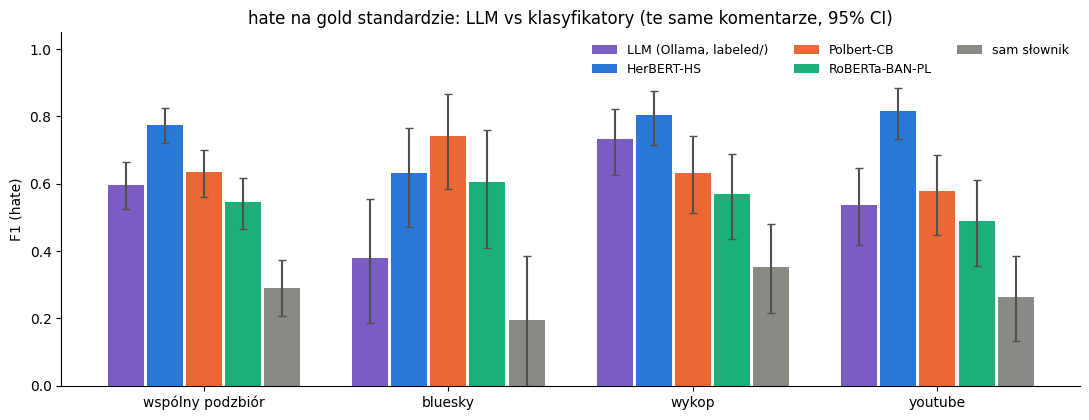

In [4]:
# F1 z 95% CI – wspólny podzbiór i per platforma
scopes = list(res["zakres"].unique())
names = list(METHODS)
colors = ["#7a5cc4", "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"]
fig, ax = plt.subplots(figsize=(11, 4.3))
w = 0.8 / len(names)
for i, name in enumerate(names):
    e = res[res["metoda"] == name].set_index("zakres").reindex(scopes)
    x = np.arange(len(scopes)) + (i - (len(names) - 1) / 2) * w
    lo = (e["f1"] - e["f1_ci95"].map(lambda v: v[0])).clip(lower=0)
    hi = (e["f1_ci95"].map(lambda v: v[1]) - e["f1"]).clip(lower=0)
    ax.bar(x, e["f1"], w * 0.92, color=colors[i % len(colors)], label=name, yerr=[lo, hi], capsize=3, ecolor="#52514e")
ax.set_xticks(range(len(scopes)), scopes)
ax.set_ylim(0, 1.05); ax.set_ylabel("F1 (hate)")
ax.set_title("hate na gold standardzie: LLM vs klasyfikatory (te same komentarze, 95% CI)")
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, ncol=3, fontsize=9)
plt.tight_layout()
fig.savefig(OUT / "hate_llm_vs_models.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Czy różnice są istotne? (LLM vs każda metoda, te same komentarze)

In [5]:
def compare(data, scope):
    out = []
    a = data[METHODS[REFERENCE]].values
    for name, col in METHODS.items():
        if name == REFERENCE:
            continue
        b = data[col].values
        y = data["gold"].values
        ci, p_boot = boot_diff(y, a, b)
        n01, n10, p_mc = mcnemar(y, a, b)
        out.append({"zakres": scope, "porównanie": f"{REFERENCE} vs {name}", "n": len(y),
                    "F1 ref": round(scores(y, a)["f1"], 3), "F1 metody": round(scores(y, b)["f1"], 3),
                    "ΔF1 (ref − metoda)": round(scores(y, a)["f1"] - scores(y, b)["f1"], 3), "ΔF1 95% CI": ci,
                    "p (bootstrap ΔF1)": p_boot, "tylko ref trafił": n01, "tylko metoda trafiła": n10, "p (McNemar)": p_mc})
    return out


cmp_rows = compare(common, "wspólny podzbiór")
for plat, x in common.groupby("platform"):
    cmp_rows += compare(x, plat)
cmp = pd.DataFrame(cmp_rows)
for c in ["p (bootstrap ΔF1)", "p (McNemar)"]:
    cmp[c.replace("p (", "p Holm (")] = cmp.groupby("zakres")[c].transform(lambda s: multipletests(s, method="holm")[1])
show = cmp.copy()
for c in [c for c in show.columns if c.startswith("p ")]:
    show[c] = show[c].map(lambda v: f"{v:.3g}")
display(show.set_index(["zakres", "porównanie"]))

n  F1 ref  F1 metody  ΔF1 (ref − metoda)        ΔF1 95% CI p (bootstrap ΔF1)  tylko ref trafił  tylko metoda trafiła p (McNemar) p Holm (bootstrap ΔF1)  \
zakres           porównanie                                                                                                                                                                                            
wspólny podzbiór LLM (Ollama, labeled/) vs HerBERT-HS      262   0.597      0.775              -0.178   [-0.25, -0.114]            0.0005                21                    52    0.000371                  0.002   
                 LLM (Ollama, labeled/) vs Polbert-CB      262   0.597      0.635              -0.038   [-0.123, 0.045]             0.397                33                    42       0.356                  0.397   
                 LLM (Ollama, labeled/) vs RoBERTa-BAN-PL  262   0.597      0.545               0.052    [-0.027, 0.13]             0.181                30                    28       0.896                  0.362   
                 LLM (Ollama, labeled/) vs sam słownik     262   0.597      0.290               0.306    [0.228, 0.392]            0.0005                47                    15    5.78e-05                  0.002   
bluesky          LLM (Ollama, labeled/) vs HerBERT-HS       67   0.381      0.633              -0.252  [-0.451, -0.048]             0.015                 9                    13       0.523                  0.045   
                 LLM (Ollama, labeled/) vs Polbert-CB       67   0.381      0.741              -0.360  [-0.555, -0.158]            0.0005                 3                    15     0.00754                  0.002   
                 LLM (Ollama, labeled/) vs RoBERTa-BAN-PL   67   0.381      0.605              -0.224  [-0.426, -0.013]             0.038                 3                    12      0.0352                   0.06   
                 LLM (Ollama, labeled/) vs sam słownik      67   0.381      0.194               0.187    [0.019, 0.377]              0.03                 5                     6           1                   0.06   
wykop            LLM (Ollama, labeled/) vs HerBERT-HS      102   0.734      0.803              -0.069   [-0.162, 0.012]             0.097                 8                    13       0.383                  0.158   
                 LLM (Ollama, labeled/) vs Polbert-CB      102   0.734      0.632               0.102    [-0.01, 0.219]             0.079                15                     9       0.307                  0.158   
                 LLM (Ollama, labeled/) vs RoBERTa-BAN-PL  102   0.734      0.571               0.163    [0.042, 0.285]             0.008                17                     7      0.0639                  0.024   
                 LLM (Ollama, labeled/) vs sam słownik     102   0.734      0.354               0.380    [0.252, 0.518]            0.0005                26                     4    5.95e-05                  0.002   
youtube          LLM (Ollama, labeled/) vs HerBERT-HS       93   0.536      0.816              -0.280  [-0.393, -0.168]            0.0005                 4                    26    5.95e-05                  0.002   
                 LLM (Ollama, labeled/) vs Polbert-CB       93   0.536      0.580              -0.044   [-0.188, 0.099]              0.58                15                    18       0.728                  0.884   
                 LLM (Ollama, labeled/) vs RoBERTa-BAN-PL   93   0.536      0.489               0.047   [-0.066, 0.169]             0.442                10                     9           1                  0.884   
                 LLM (Ollama, labeled/) vs sam słownik      93   0.536      0.263               0.273      [0.155, 0.4]            0.0005                16                     5      0.0266                  0.002   

                                                          p Holm (McNemar)  
zakres           porównanie                                                 
wspólny podzbiór L

## 3. YouTube i Bluesky: tylko komentarze, które LLM ocenił (obecne w `labeled/`)

Uczciwsze porównanie definicji: na tych komentarzach LLM rzeczywiście oceniał hejt, a nie wpisywał 0 za „nie o migracji”.

In [6]:
inside = common[(common["platform"].isin(["youtube", "bluesky"])) & (common["llm_status"] == "etykieta LLM")]
outside = common[(common["platform"].isin(["youtube", "bluesky"])) & (common["llm_status"] != "etykieta LLM")]
print(f"YouTube + Bluesky: w labeled/ {len(inside)}, poza labeled/ (LLM: nie o migracji -> 0) {len(outside)}; "
      f"gold hate = 1 poza labeled/: {int(outside['gold'].sum())} – tych LLM z definicji nie liczy")
if len(inside) >= 10:
    t = pd.DataFrame(table(inside, "YouTube+Bluesky, w labeled/"))
    t[NUM] = t[NUM].astype(float).round(3)
    display(t[cols].set_index("metoda").sort_values("f1", ascending=False))
    show = pd.DataFrame(compare(inside, "YouTube+Bluesky, w labeled/"))
    for c in [c for c in show.columns if c.startswith("p ")]:
        show[c] = show[c].map(lambda v: f"{v:.3g}")
    display(show.set_index("porównanie"))

YouTube + Bluesky: w labeled/ 69, poza labeled/ (LLM: nie o migracji -> 0) 91; gold hate = 1 poza labeled/: 47 – tych LLM z definicji nie liczy


,n,accuracy,precision,recall,f1,f1_ci95,mcc
metoda,,,,,,,
HerBERT-HS,69,0.681,0.735,0.800,0.766,"[0.659, 0.852]",0.271
"LLM (Ollama, labeled/)",69,0.652,0.723,0.756,0.739,"[0.626, 0.835]",0.219
RoBERTa-BAN-PL,69,0.623,0.852,0.511,0.639,"[0.5, 0.763]",0.336
Polbert-CB,69,0.594,0.774,0.533,0.632,"[0.492, 0.747]",0.231
sam słownik,69,0.507,0.867,0.289,0.433,"[0.261, 0.58]",0.237


,zakres,n,F1 ref,F1 metody,ΔF1 (ref − metoda),ΔF1 95% CI,p (bootstrap ΔF1),tylko ref trafił,tylko metoda trafiła,p (McNemar)
porównanie,,,,,,,,,,
"LLM (Ollama, labeled/) vs HerBERT-HS","YouTube+Bluesky, w labeled/",69,0.739,0.766,-0.027,"[-0.097, 0.041]",0.523,3,5,0.727
"LLM (Ollama, labeled/) vs Polbert-CB","YouTube+Bluesky, w labeled/",69,0.739,0.632,0.108,"[0.002, 0.227]",0.047,12,8,0.503
"LLM (Ollama, labeled/) vs RoBERTa-BAN-PL","YouTube+Bluesky, w labeled/",69,0.739,0.639,0.100,"[-0.009, 0.217]",0.075,11,9,0.824
"LLM (Ollama, labeled/) vs sam słownik","YouTube+Bluesky, w labeled/",69,0.739,0.433,0.306,"[0.154, 0.473]",0.0005,21,11,0.11


## 4. Zgodność metod między sobą (κ Cohena, wspólny podzbiór)

In [7]:
from itertools import combinations


def kappa(a, b):
    a, b = np.asarray(a, int), np.asarray(b, int)
    po = (a == b).mean(); pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return (po - pe) / (1 - pe) if pe < 1 else np.nan


cols_k = {"gold": common["gold"].values, **{n: common[c].values for n, c in METHODS.items()}}
k = pd.DataFrame(1.0, index=list(cols_k), columns=list(cols_k))
for a, b in combinations(cols_k, 2):
    k.loc[a, b] = k.loc[b, a] = round(kappa(cols_k[a], cols_k[b]), 3)
display(k)

,gold,"LLM (Ollama, labeled/)",HerBERT-HS,Polbert-CB,RoBERTa-BAN-PL,sam słownik
gold,1.000,0.280,0.458,0.344,0.290,0.127
"LLM (Ollama, labeled/)",0.280,1.000,0.466,0.370,0.480,0.379
HerBERT-HS,0.458,0.466,1.000,0.458,0.323,0.170
Polbert-CB,0.344,0.370,0.458,1.000,0.491,0.374
RoBERTa-BAN-PL,0.290,0.480,0.323,0.491,1.000,0.532
sam słownik,0.127,0.379,0.170,0.374,0.532,1.000


## 5. Wniosek (generowany automatycznie) i zapis

In [8]:
main = res[res["zakres"] == "wspólny podzbiór"].sort_values(["f1", "mcc"], ascending=False)
best = main.iloc[0]
lines = [f"Na wspólnym podzbiorze (n = {int(best['n'])}) najwyższe F1 dla hate ma {best['metoda']}: "
         f"{best['f1']:.3f} {best['f1_ci95']} (MCC {best['mcc']:.3f})."]
for _, r in cmp[cmp["zakres"] == "wspólny podzbiór"].iterrows():
    sig = "istotna" if r["p Holm (bootstrap ΔF1)"] < ALPHA else "nieistotna"
    lines.append(f"- {r['porównanie']}: ΔF1 = {r['ΔF1 (ref − metoda)']:+.3f} {r['ΔF1 95% CI']}, różnica {sig} "
                 f"(p Holm = {r['p Holm (bootstrap ΔF1)']:.3g}; McNemar p Holm = {r['p Holm (McNemar)']:.3g})")
for plat in ["wykop", "bluesky", "youtube"]:
    x = res[res["zakres"] == plat].sort_values("f1", ascending=False)
    if len(x):
        lines.append(f"- {plat} (n = {int(x.iloc[0]['n'])}): najlepsze F1 – {x.iloc[0]['metoda']} {x.iloc[0]['f1']:.3f}; "
                     f"LLM {x[x['metoda'] == REFERENCE]['f1'].iloc[0]:.3f}, HerBERT {x[x['metoda'] == 'HerBERT-HS']['f1'].iloc[0]:.3f}")
print("\n".join(lines))

res.to_csv(OUT / "hate_llm_vs_models.csv", index=False, encoding="utf-8-sig")
cmp.to_csv(OUT / "hate_llm_vs_models_tests.csv", index=False, encoding="utf-8-sig")
(OUT / "hate_llm_vs_models.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\nzapisano: hate_llm_vs_models.csv, hate_llm_vs_models_tests.csv, hate_llm_vs_models.md, hate_llm_vs_models.png")

Na wspólnym podzbiorze (n = 262) najwyższe F1 dla hate ma HerBERT-HS: 0.775 [0.721, 0.825] (MCC 0.458).
- LLM (Ollama, labeled/) vs HerBERT-HS: ΔF1 = -0.178 [-0.25, -0.114], różnica istotna (p Holm = 0.002; McNemar p Holm = 0.00111)
- LLM (Ollama, labeled/) vs Polbert-CB: ΔF1 = -0.038 [-0.123, 0.045], różnica nieistotna (p Holm = 0.397; McNemar p Holm = 0.711)
- LLM (Ollama, labeled/) vs RoBERTa-BAN-PL: ΔF1 = +0.052 [-0.027, 0.13], różnica nieistotna (p Holm = 0.362; McNemar p Holm = 0.896)
- LLM (Ollama, labeled/) vs sam słownik: ΔF1 = +0.306 [0.228, 0.392], różnica istotna (p Holm = 0.002; McNemar p Holm = 0.000231)
- wykop (n = 102): najlepsze F1 – HerBERT-HS 0.803; LLM 0.734, HerBERT 0.803
- bluesky (n = 67): najlepsze F1 – Polbert-CB 0.741; LLM 0.381, HerBERT 0.633
- youtube (n = 93): najlepsze F1 – HerBERT-HS 0.816; LLM 0.536, HerBERT 0.816

zapisano: hate_llm_vs_models.csv, hate_llm_vs_models_tests.csv, hate_llm_vs_models.md, hate_llm_vs_models.png
